# Pipeline Benchmarking

End-to-end workflow:
1. Load tasks
2. Run your pipeline to generate solutions
3. Score solutions with LLM-as-judge
4. Review results and compute accuracy

In [1]:
import os
from pathlib import Path
from datetime import datetime

from dotenv import load_dotenv
load_dotenv()

from agenticeoecosystem import (
    MODEL_CLAUDE_SONNET,
    ScoreValues,
    TaskSet,
    generate_solutions,
    evaluate_solutions,
    save_conversation_to_html
)

## 1. Load tasks

In [2]:
# Load the task set you want to evaluate
from agenticeoecosystem.definitions import TASKS_FOLDER, GEOBENCH_RESULTS

TASKS_FILE = TASKS_FOLDER / 'eo_benchmark_tasks.json'   # TODO: set your filename

tasks = TaskSet.read_from_file(TASKS_FILE, folder=TASKS_FOLDER)
print(f'Loaded {len(tasks)} tasks')
print(tasks.get_label_counts())

Loaded 77 tasks
{<TaskLabels.TOOL_GROUNDING: 'Tool Grounding'>: 20, <TaskLabels.SEQUENTIAL_REASONING: 'Sequential Reasoning'>: 10, <TaskLabels.CROSS_AGENT_SYNTHESIS: 'Cross-agent Synthesis'>: 7, <TaskLabels.SCOPE_AWARENESS: 'Scope Awareness'>: 20, <TaskLabels.PLACEHOLDER: 'Placeholder'>: 20}


In [3]:
# (Optional) sample a stratified subset for a quick run
# tasks = tasks.sample_stratified(num_samples=20)

# (Optional) filter to a specific label
# tasks = tasks.select_by_labels(['Category A'])

print(f'Running on {len(tasks)} tasks')

Running on 77 tasks


### Browse available tasks

In [4]:
import pandas as pd
from IPython.display import display, HTML
from agenticeoecosystem.definitions import TASKS_FOLDER
from agenticeoecosystem.evaluation.dataclasses import TaskSet

_browse = TaskSet.read_from_file('eo_benchmark_tasks.json', folder=TASKS_FOLDER)

# ── Overview table ────────────────────────────────────────────────────────────
_rows = []
for t in _browse:
    label = t.task_labels[0].value if t.task_labels else "—"
    n_refs = len(t.reference_solutions or [])
    n_steps = len(t.reference_solutions[0].steps) if t.reference_solutions else 0
    _rows.append({
        "ID":      t.task_ID,
        "Label":   label,
        "Steps":   n_steps,
        "Alt solutions": n_refs,
        "Task":    t.task_text,
    })

df_overview = pd.DataFrame(_rows)
with pd.option_context("display.max_colwidth", 80):
    display(HTML(df_overview.to_html(index=False)))

# ── Detailed view grouped by label ───────────────────────────────────────────
LABEL_ORDER = [
    "Tool Grounding",
    "Sequential Reasoning",
    "Cross-agent Synthesis",
    "Scope Awareness",
    "Placeholder",
]

for label in LABEL_ORDER:
    group = [t for t in _browse if t.task_labels and t.task_labels[0].value == label]
    if not group:
        continue
    print(f"\n{'━' * 72}")
    print(f"  {label}  ({len(group)} task{'s' if len(group) != 1 else ''})")
    print(f"{'━' * 72}")
    for t in group:
        print(f"\n  [{t.task_ID}]")
        print(f"  {t.task_text}")
        if t.reference_solution_description:
            print(f"  ↳ {t.reference_solution_description}")
        for r_idx, ref in enumerate(t.reference_solutions or []):
            prefix = f"  Ref {r_idx + 1}: " if len(t.reference_solutions) > 1 else "  Ref:    "
            for s_idx, step in enumerate(ref.steps):
                args = ", ".join(f"{k}={v!r}" for k, v in step.arguments.items())
                indent = prefix if s_idx == 0 else " " * len(prefix)
                print(f"{indent}{s_idx + 1}. {step.function_name}({args})")
            if not ref.steps:
                print(f"{prefix}(no tool calls expected)")

ID,Label,Steps,Alt solutions,Task
TASK_260419_000001_100001,Tool Grounding,1,1,List all available themes in the EO Dashboard.
TASK_260419_000002_100002,Tool Grounding,2,2,Find narratives about wildfires and list the STAC collection codes they reference.
TASK_260419_000003_100003,Tool Grounding,2,2,Retrieve the full content of any narrative about air quality.
TASK_260419_000004_100004,Sequential Reasoning,1,1,"Download a Sentinel-2 RGB satellite image of central Rome (approximately 41.9°N, 12.5°E) for the period January to March 2023, at 10 m resolution with less than 20% cloud cover."
TASK_260419_000005_100005,Cross-agent Synthesis,4,1,"Find a narrative about Covid-19 economic impacts, retrieve its STAC collection items, and then download a GEE satellite image for a relevant location mentioned in the narrative."
TASK_260419_000006_100006,Tool Grounding,1,1,Which narratives in the EO Dashboard reference the indicator collection EO:EEA:DAT:CLMS_CORINE_CLCPLUS_RASTER_2018_V1_1?
TASK_260419_000007_100007,Scope Awareness,0,1,What is the current weather on Mars?
TASK_260419_000008_100008,Tool Grounding,2,2,Find EO Dashboard narratives about greenhouse gas emissions and list the STAC collection codes they reference.
TASK_260419_000009_100009,Tool Grounding,2,2,Find an EO Dashboard narrative about deforestation and retrieve its full text content.
TASK_260419_000010_100010,Tool Grounding,1,1,Which EO Dashboard narratives reference the sea ice dataset with indicator code EO:ESA:DAT:CRYOSAT:SEA_ICE_THICKNESS?



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Tool Grounding  (20 tasks)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  [TASK_260419_000001_100001]
  List all available themes in the EO Dashboard.
  ↳ Agent should call list_themes to retrieve the full set of themes.
  Ref:    1. list_themes()

  [TASK_260419_000002_100002]
  Find narratives about wildfires and list the STAC collection codes they reference.
  ↳ Agent searches for wildfire narratives then extracts their STAC indicators.
  Ref 1: 1. search_narratives(keyword='wildfire')
         2. get_narrative_indicators(narrative_title='<any wildfire narrative title>')
  Ref 2: 1. search_narratives(keyword='fire')
         2. get_narrative_indicators(narrative_title='<any fire narrative title>')

  [TASK_260419_000003_100003]
  Retrieve the full content of any narrative about air quality.
  ↳ Agent finds a relevant narrative and fetches its full markdown content.
  Ref 1: 1. se

## 2. Generate solutions with your pipeline

In [5]:
sub_tasks = tasks.select_by_labels(['Tool Grounding'])

In [7]:
MODEL = os.getenv("MAIN_MODEL_NAME", "EVE-Instruct")   # set MAIN_MODEL_NAME in .env
MODEL_PROVIDER = "eve"                                 # "eve" | "openai" | "custom" | "ollama"
TEMPERATURE = 0.0
OUTPUT_FILE = f"{datetime.now().strftime('%Y%m%d_%H%M%S')}_{MODEL}_solutions.json"

from agenticeoecosystem.definitions import GEOBENCH_RESULTS
RESULTS_FOLDER = GEOBENCH_RESULTS

tasks, total_in, total_out = generate_solutions(
    tasks=sub_tasks,
    model=MODEL,
    temperature=TEMPERATURE,
    model_provider=MODEL_PROVIDER,
    output_filename=OUTPUT_FILE,
    skip_solved=True,
    wait_between_tasks=0.0,   # Increase if you hit rate limits
)

print(f'Total tokens — in: {total_in}, out: {total_out}')

Generating solutions:   0%|          | 0/20 [00:00<?, ?it/s]


Task TASK_260419_000001_100001: List all available themes in the EO Dashboard.
[TOOL CALL] get_eo_stac_data with request: List all available themes in the EO Dashboard.
[TOOL RESULT] Here are the available themes in the EO Dashboard along with the number of narratives they contain:

1. **Agriculture** – 2 narratives
2. **Atmosphere** – 5 narratives
3. **Biomass** – 3 narratives
4. **COVID-19** – 6 narratives
5. **Cryosphere** – 8 narratives
6. **Economy** – 2 narratives
7. **Extreme Events** – 6 narratives
8. **Oceans** – 9 narratives


Generating solutions:   5%|▌         | 1/20 [00:21<06:52, 21.70s/it]

  → Done. Tokens: 4083 in / 380 out
1. list_themes()

Task TASK_260419_000002_100002: Find narratives about wildfires and list the STAC collection codes they reference.
[TOOL CALL] get_eo_stac_data with request: Find narratives about wildfires and list the STAC collection codes they reference.
[TOOL RESULT] I searched for narratives about wildfires, but unfortunately, no narratives were found matching that theme.


Generating solutions:  10%|█         | 2/20 [00:36<05:22, 17.91s/it]

  → Done. Tokens: 3322 in / 88 out
1. search_narratives(theme='wildfires')

Task TASK_260419_000003_100003: Retrieve the full content of any narrative about air quality.
[TOOL CALL] get_eo_stac_data with request: Retrieve the full content of any narrative about air quality.
[TOOL RESULT] Here is the full content of the narrative titled **"Covid-19 Impacts on Air Quality"**:

---

### **Frontmatter Metadata**
- **Cover Image**: [Hero Image](https://raw.githubusercontent.com/eurodatacube/eodash-assets/main/stories/covid-no2/hero.jpg)
- **Date**: 2025-01-01
- **Theme**: Covid-19
- **Tags**: no2
- **Official**: Yes
- **STAC Collection Codes**:
  - `N1_NO2_trilateral`
  - `N1_NO2`
  - `CV_Covid_19_cases`

---

### **Narrative Content**

#### **Title**: Covid-19 Impacts on Air Quality
#### **Subtitle**: Effect of Lockdown on Nitrogen Dioxide

---

> **Collaboration Note**:
> This trilateral story is a collaboration between the [European Space Agency (ESA)](https://www.esa.int), [NASA](https:

... (32 outputs left out)

Generating solutions:  95%|█████████▌| 19/20 [22:49<01:48, 108.90s/it]

  → Done. Tokens: 4547 in / 204 out
1. search_narratives(theme='disaster')
2. search_narratives(keyword='disaster')

Task TASK_260419_000040_100040: Find an EO Dashboard narrative about economic recovery or human mobility patterns observed from space and retrieve its full text content.
[TOOL CALL] get_eo_stac_data with request: Find an EO Dashboard narrative about economic recovery or human mobility patterns observed from space and retrieve its full text content.
[TOOL RESULT] It seems there are no narratives available that match the keywords "economic recovery" or "mobility." Would you like me to explore other themes or keywords that might be relevant to your interest in human mobility patterns or economic recovery observed from space? For example, we could look into themes like "urban development," "transportation," or "socioeconomic indicators."


Generating solutions: 100%|██████████| 20/20 [23:15<00:00, 69.77s/it] 

  → Done. Tokens: 4625 in / 262 out
1. search_narratives(keyword='economic recovery', theme='human mobility')
2. search_narratives(keyword='mobility', theme='')

Done. Total tokens — input: 92114, output: 11669
Total tokens — in: 92114, out: 11669


## 3. (Optional) Save HTML conversation logs

In [1]:
# If your pipeline runner captures conversation_history, save it here.
# This cell is optional — skip if you don't need HTML reports.

run_folder = RESULTS_FOLDER / OUTPUT_FILE.replace('.json', '')

for task in tasks:
    # TODO: pass the real conversation history if you captured it
    save_conversation_to_html(task, conversation_history=None, output_folder=run_folder)

print(f'HTML reports saved to {run_folder}')

NameError: name 'RESULTS_FOLDER' is not defined

## 4. Evaluate solutions with LLM-as-judge

In [9]:
EVALUATOR_MODEL = os.getenv("MAIN_MODEL_NAME", "EVE-Instruct")   # can differ from pipeline model
# Switch evaluator backend by setting EVALUATOR_PROVIDER in .env: "eve" | "openai" | "custom" | "ollama"

tasks = evaluate_solutions(
    tasks=tasks,
    model=EVALUATOR_MODEL,
    temperature=0.0,
    output_filename=OUTPUT_FILE,
    skip_evaluated=True,
)

Evaluating solutions: 100%|██████████| 20/20 [01:34<00:00,  4.74s/it]


## 5. Results summary

In [13]:
import pandas as pd

summary = tasks.score_summary()
print('=== Score summary ===')
for scorer, stats in summary.items():
    print(f'\n{scorer}:')
    for k, v in stats.items():
        print(f'  {k}: {v}')

=== Score summary ===

LLM:
  n: 1
  match: 0
  partial: 0
  no_match: 1
  accuracy_full: 0.0
  accuracy_partial_or_full: 0.0

Human:
  n: 0


In [14]:
# Breakdown by label
rows = []
for task in tasks:
    rows.append({
        'task_ID': task.task_ID,
        'labels': str(task.task_labels),
        'score_LLM': task.match_score_LLM,
        'score_Human': task.match_score_Human,
        'reasoning': task.match_reasoning_LLM,
    })

df = pd.DataFrame(rows)
df

,task_ID,labels,score_LLM,score_Human,reasoning
0,TASK_260419_000001_100001,[<TaskLabels.TOOL_GROUNDING: 'Tool Grounding'>],0.0,None,"The candidate solution is empty, failing to fu..."
1,TASK_260419_000002_100002,[<TaskLabels.TOOL_GROUNDING: 'Tool Grounding'>],NaN,None,None
2,TASK_260419_000003_100003,[<TaskLabels.TOOL_GROUNDING: 'Tool Grounding'>],NaN,None,None
3,TASK_260419_000006_100006,[<TaskLabels.TOOL_GROUNDING: 'Tool Grounding'>],NaN,None,None
4,TASK_260419_000008_100008,[<TaskLabels.TOOL_GROUNDING: 'Tool Grounding'>],NaN,None,None
5,TASK_260419_000009_100009,[<TaskLabels.TOOL_GROUNDING: 'Tool Grounding'>],NaN,None,None
6,TASK_260419_000010_100010,[<TaskLabels.TOOL_GROUNDING: 'Tool Grounding'>],NaN,None,None
7,TASK_260419_000011_100011,[<TaskLabels.TOOL_GROUNDING: 'Tool Grounding'>],NaN,None,None
8,TASK_260419_000012_100012,[<TaskLabels.TOOL_GROUNDING: 'Tool Grounding'>],NaN,None,None
9,TASK_260419_000013_100013,[<TaskLabels.TOOL_GROUNDING: 'Tool Grounding'>],NaN,None,None


In [ ]:
# Accuracy by label (LLM scores)
df['is_match'] = df['score_LLM'] == ScoreValues.MATCH
df.groupby('labels')['is_match'].mean().sort_values()

## 6. Manual review

Use this cell to inspect individual tasks and add human scores.

In [ ]:
# Pick a task to review manually
TASK_INDEX = 0
task = tasks[TASK_INDEX]
print(task)
print('\n--- Generated solution ---')
print(task.generated_solution)
print('\n--- Reference solution(s) ---')
for i, ref in enumerate(task.reference_solutions or []):
    print(f'Reference {i+1}:')
    print(ref)

In [ ]:
# Add your manual score here
task.match_score_Human = ScoreValues.MATCH          # 0 / 1 / 2
task.match_reasoning_Human = 'Looks correct to me.'

# Save
tasks.save_to_file(OUTPUT_FILE, folder=RESULTS_FOLDER)
print('Saved.')

## 7. Benchmark Results (multi-model comparison)

Load and visualize the `model_comparison.csv` produced by `scripts/build_table.py` / `scripts/benchmark.sh`.

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from pathlib import Path
from IPython.display import display, HTML

RESULTS_DIR = Path("../output/geobenchX/run_20260427_212717")
csv_path = RESULTS_DIR / "model_comparison_cleaned.csv"

df = pd.read_csv(csv_path)
df = df.set_index("model")

# Drop rows where no tasks were attempted
df = df[df["tasks_attempted"] > 0]

print(f"Models with results: {list(df.index)}")
print(f"Total columns: {len(df.columns)}")
df[["tasks_attempted", "avg_steps", "total_input_tokens", "total_output_tokens"]]

Models with results: ['DeepSeek-R1-14B', 'EVE-Instruct', 'Gemma3-12B', 'Nemotron-2-12B', 'Phi4-Mini', 'Qwen2.5-14B', 'Qwen3-14B']
Total columns: 22


,tasks_attempted,avg_steps,total_input_tokens,total_output_tokens
model,,,,
DeepSeek-R1-14B,25,0.0,6170,14601
EVE-Instruct,25,1.3,559547,37159
Gemma3-12B,25,0.0,6206,9094
Nemotron-2-12B,25,0.7,300742,718230
Phi4-Mini,25,0.0,6072,3797
Qwen2.5-14B,25,1.4,294132,20159
Qwen3-14B,25,2.5,682651,92479


### Accuracy heatmap — full match (score = 2)

/tmp/ipykernel_797823/2479138147.py:39: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


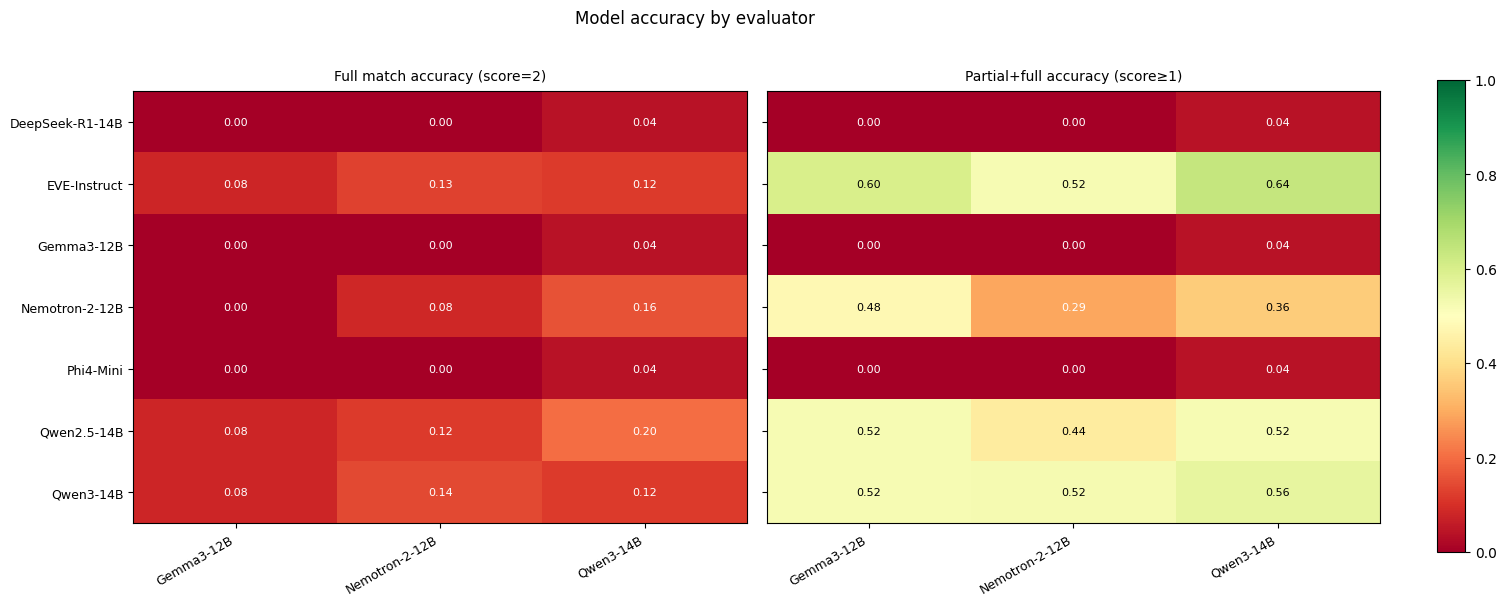

In [ ]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Extract accuracy columns — one column per evaluator
acc_full_cols    = [c for c in df.columns if c.startswith("accuracy_full [")]
acc_partial_cols = [c for c in df.columns if c.startswith("accuracy_partial+full [")]

evaluator_names = [c.split("[")[1].rstrip("]") for c in acc_full_cols]

acc_full    = df[acc_full_cols].copy()
acc_partial = df[acc_partial_cols].copy()
acc_full.columns    = evaluator_names
acc_partial.columns = evaluator_names

fig, axes = plt.subplots(1, 2, figsize=(14, max(3, len(df) * 0.7 + 1)), sharey=True)

for ax, data, title in [
    (axes[0], acc_full,    "Full match accuracy (score=2)"),
    (axes[1], acc_partial, "Partial+full accuracy (score≥1)"),
]:
    im = ax.imshow(data.values.astype(float), vmin=0, vmax=1, cmap="RdYlGn", aspect="auto")
    ax.set_xticks(range(len(evaluator_names)))
    ax.set_xticklabels(evaluator_names, rotation=30, ha="right", fontsize=9)
    ax.set_yticks(range(len(df.index)))
    ax.set_yticklabels(df.index, fontsize=9)
    ax.set_title(title, fontsize=10, pad=8)
    # Annotate cells
    for r in range(data.shape[0]):
        for c in range(data.shape[1]):
            val = data.values[r, c]
            if not np.isnan(val):
                ax.text(c, r, f"{val:.2f}", ha="center", va="center", fontsize=8,
                        color="black" if 0.3 < val < 0.8 else "white")
            else:
                ax.text(c, r, "—", ha="center", va="center", fontsize=8, color="gray")


cbar_ax = fig.add_axes([1.03, 0.1, 0.02, 0.8])  # [left, bottom, width, height]
fig.colorbar(im, cax=cbar_ax)
plt.suptitle("Model accuracy by evaluator", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

### Score distribution — match / partial / no-match per model

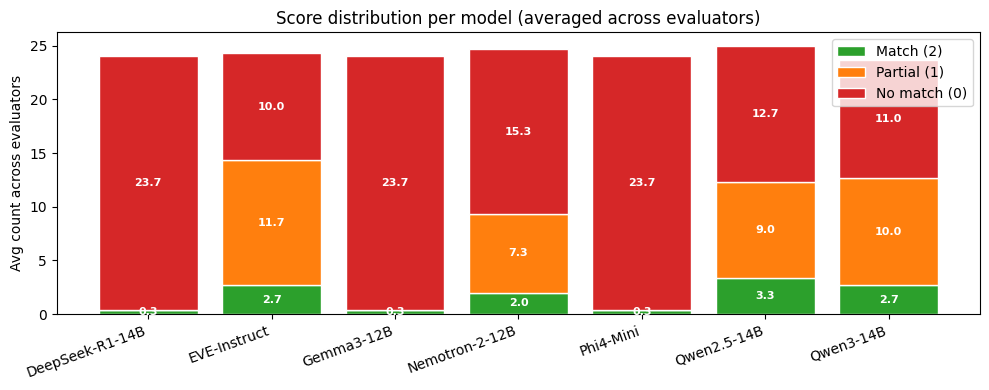

In [6]:
# Stacked bar: match / partial / no_match averaged across evaluators, per model
match_cols    = [c for c in df.columns if c.startswith("match (2) [")]
partial_cols  = [c for c in df.columns if c.startswith("partial (1) [")]
nomatch_cols  = [c for c in df.columns if c.startswith("no_match (0) [")]

match_avg   = df[match_cols].mean(axis=1)
partial_avg = df[partial_cols].mean(axis=1)
nomatch_avg = df[nomatch_cols].mean(axis=1)

stack = pd.DataFrame({
    "Match (2)":    match_avg,
    "Partial (1)":  partial_avg,
    "No match (0)": nomatch_avg,
})

fig, ax = plt.subplots(figsize=(10, 4))
bottom = np.zeros(len(stack))
colors = ["#2ca02c", "#ff7f0e", "#d62728"]
for col, color in zip(stack.columns, colors):
    ax.bar(stack.index, stack[col], bottom=bottom, label=col, color=color, edgecolor="white")
    for i, (v, b) in enumerate(zip(stack[col], bottom)):
        if v > 0.05:
            ax.text(i, b + v / 2, f"{v:.1f}", ha="center", va="center", fontsize=8, color="white", fontweight="bold")
    bottom += stack[col].values

ax.set_ylabel("Avg count across evaluators")
ax.set_title("Score distribution per model (averaged across evaluators)")
ax.set_xticks(range(len(stack.index)))
ax.set_xticklabels(stack.index, rotation=20, ha="right")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### Performance by task category

In [37]:
import json

BASE = Path("../output/geobenchX/run_20260427_212717")
MODELS = ['DeepSeek-R1-14B', 'EVE-Instruct', 'Gemma3-12B', 'Nemotron-2-12B', 'Phi4-Mini', 'Qwen2.5-14B', 'Qwen3-14B']
EVALUATORS = ['Gemma3-12B', 'Nemotron-2-12B', 'Qwen3-14B']
EXCLUDED = {
    'TASK_260419_000004_100004', 'TASK_260419_000005_100005',
    'TASK_260427_000010_200010', 'TASK_260427_000013_200013', 'TASK_260427_000035_200035',
}

rows = []
for model in MODELS:
    with open(BASE / f"results_{model}.json") as f:
        data = json.load(f)
    for t in data["tasks"]:
        if t["task_ID"] in EXCLUDED:
            continue
        category = t["task_labels"][0] if t.get("task_labels") else "Unknown"
        did_run = t.get("generated_solution") not in [None, "", []]
        scores = t.get("evaluator_scores") or {}
        for ev in EVALUATORS:
            rows.append({
                "task_ID": t["task_ID"],
                "category": category,
                "model": model,
                "evaluator": ev,
                "score": scores.get(ev),
                "ran": did_run,
            })

df_tasks = pd.DataFrame(rows)
print(f"Rows: {len(df_tasks)}")
print(df_tasks.groupby("category")["task_ID"].nunique().sort_values(ascending=False).rename("n_tasks"))

Rows: 525
category
Tool Grounding           11
Cross-agent Synthesis     7
Sequential Reasoning      5
Scope Awareness           2
Name: n_tasks, dtype: int64


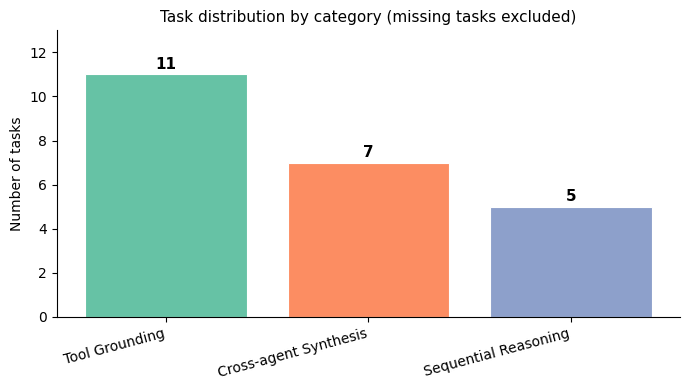

In [38]:
# Task distribution by category
cat_counts = (
    df_tasks[df_tasks["model"] == MODELS[0]]
    .groupby("category")["task_ID"].nunique()
    .drop(index="Scope Awareness", errors="ignore")
    .sort_values(ascending=False)
)

palette = plt.cm.Set2.colors
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(cat_counts.index, cat_counts.values,
              color=palette[:len(cat_counts)], edgecolor="white", linewidth=0.8)
for bar, v in zip(bars, cat_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
            str(v), ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_ylabel("Number of tasks")
ax.set_title("Task distribution by category (missing tasks excluded)", fontsize=11)
ax.set_xticks(range(len(cat_counts)))
ax.set_xticklabels(cat_counts.index, rotation=15, ha="right", fontsize=10)
ax.set_ylim(0, cat_counts.max() + 2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

TypeError: 'Axes' object is not subscriptable

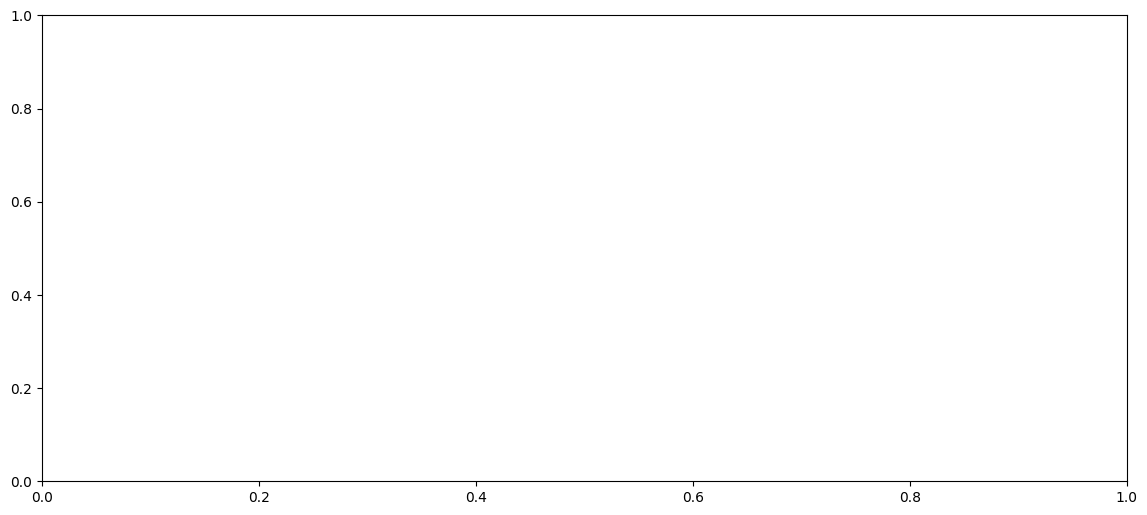

In [ ]:
# Accuracy heatmap by model × category (averaged over evaluators)
scored = df_tasks[
    df_tasks["score"].notna() & (df_tasks["category"] != "Scope Awareness")
].copy()
categories = [c for c in scored["category"].unique() if c != "Scope Awareness"]

def make_acc_matrix(condition_series):
    return (
        scored.assign(val=condition_series.astype(float))
        .groupby(["model", "category"])["val"]
        .mean()
        .unstack("category")
        .reindex(index=MODELS, columns=categories)
        .fillna(0)
    )

mat_full    = make_acc_matrix(scored["score"] == 2)
mat_partial = make_acc_matrix(scored["score"] >= 1)

fig, axes = plt.subplots(1, 1, figsize=(14, max(3, len(MODELS) * 0.65 + 1.5)), sharey=True)
for ax, mat, title in [
    (axes[0], mat_full,    "Full match accuracy (score = 2)"),
    (axes[1], mat_partial, "Partial+full accuracy (score ≥ 1)"),
]:
    im = ax.imshow(mat.values.astype(float), vmin=0, vmax=1, cmap="RdYlGn", aspect="auto")
    ax.set_xticks(range(len(categories)))
    ax.set_xticklabels(categories, rotation=25, ha="right", fontsize=9)
    ax.set_yticks(range(len(MODELS)))
    ax.set_yticklabels(MODELS, fontsize=9)
    ax.set_title(title, fontsize=10, pad=8)
    for r in range(mat.shape[0]):
        for c in range(mat.shape[1]):
            val = mat.values[r, c]
            txt_color = "black" if 0.25 < val < 0.75 else "white"
            ax.text(c, r, f"{val:.2f}", ha="center", va="center", fontsize=8, color=txt_color)

fig.subplots_adjust(right=0.88, top=0.88)
cbar_ax = fig.add_axes([0.91, 0.15, 0.015, 0.65])
fig.colorbar(im, cax=cbar_ax)
plt.suptitle("Model accuracy by task category (avg over evaluators)", fontsize=12)
plt.show()

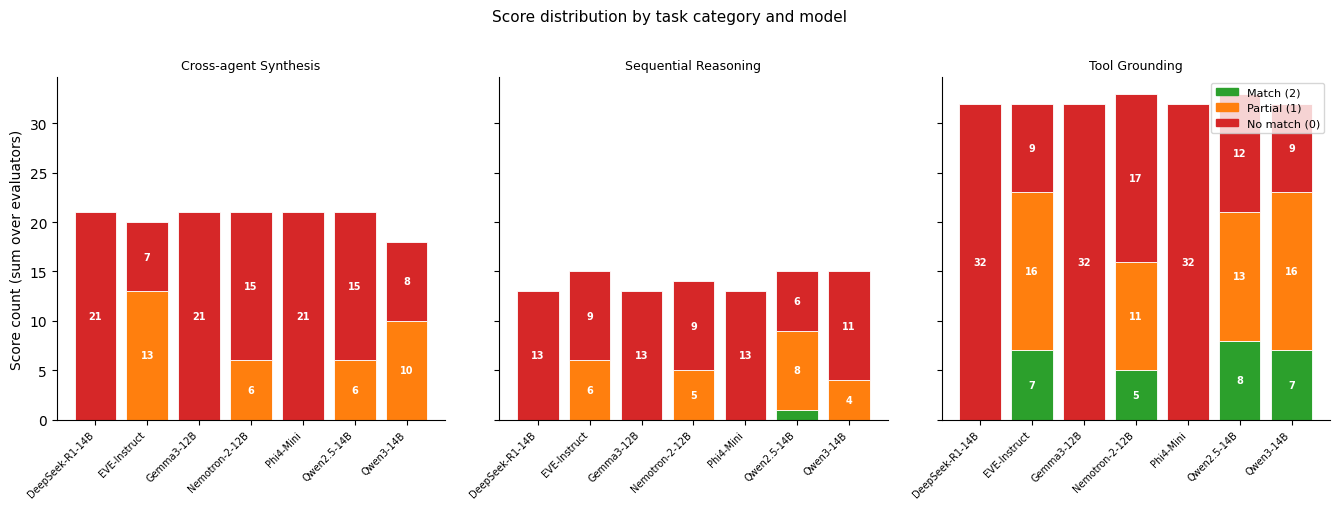

In [40]:
# Score distribution (match / partial / no-match) by category and model
categories_sorted = sorted(c for c in df_tasks["category"].unique() if c != "Scope Awareness")
n_cats = len(categories_sorted)
score_colors = {"Match (2)": "#2ca02c", "Partial (1)": "#ff7f0e", "No match (0)": "#d62728"}

fig, axes = plt.subplots(1, n_cats, figsize=(4.5 * n_cats, 5), sharey=True)
if n_cats == 1:
    axes = [axes]

for ax, cat in zip(axes, categories_sorted):
    sub = scored[scored["category"] == cat]
    agg = (
        sub.groupby("model")["score"]
        .value_counts()
        .unstack(fill_value=0)
        .reindex(columns=[2, 1, 0], fill_value=0)
        .reindex(MODELS, fill_value=0)
    )
    agg.columns = ["Match (2)", "Partial (1)", "No match (0)"]

    bottom = np.zeros(len(agg))
    x = range(len(agg))
    for col, color in score_colors.items():
        vals = agg[col].values.astype(float)
        ax.bar(x, vals, bottom=bottom, color=color, label=col, edgecolor="white", linewidth=0.6)
        for i, (v, b) in enumerate(zip(vals, bottom)):
            if v >= 1.5:
                ax.text(i, b + v / 2, str(int(v)), ha="center", va="center",
                        fontsize=7, color="white", fontweight="bold")
        bottom += vals

    ax.set_title(cat, fontsize=9, pad=6)
    ax.set_xticks(range(len(MODELS)))
    ax.set_xticklabels(MODELS, rotation=45, ha="right", fontsize=7)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Score count (sum over evaluators)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in score_colors.values()]
axes[-1].legend(handles, score_colors.keys(), loc="upper right", fontsize=8, framealpha=0.8)
plt.suptitle("Score distribution by task category and model", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

### Score per MCP server

In [ ]:
# Average normalized score per MCP server
# Tasks that span multiple servers are counted toward each server's average.

FUNCTION_TO_SERVER = {
    # EO Dashboard
    "list_themes": "EO Dashboard", "get_narrative_content": "EO Dashboard",
    "get_narrative_indicators": "EO Dashboard", "get_collection_items": "EO Dashboard",
    "search_narratives": "EO Dashboard", "compute_s2_ndvi": "EO Dashboard",
    # HybridRAG
    "hybrid_rag_retrieve": "HybridRAG",
    # GEE
    "download_satellite_image": "GEE",
    # Arxiv
    "search_papers": "Arxiv", "download_paper": "Arxiv", "read_paper": "Arxiv",
    "list_papers": "Arxiv", "get_abstract": "Arxiv", "semantic_search": "Arxiv",
    "citation_graph": "Arxiv", "watch_topic": "Arxiv", "check_alerts": "Arxiv",
    # GIS
    "compute_ndvi": "GIS", "metadata_raster": "GIS", "raster_band_statistics": "GIS",
    "clip_raster_with_shapefile": "GIS", "reproject_raster": "GIS", "zonal_statistics": "GIS",
    "raster_histogram": "GIS", "resample_raster": "GIS", "raster_algebra": "GIS",
    "extract_band": "GIS", "focal_statistics": "GIS", "get_raster_crs": "GIS",
    "transform_coordinates": "GIS", "calculate_geodetic_distance": "GIS",
    "calculate_geodetic_area": "GIS", "get_utm_zone": "GIS", "get_utm_crs": "GIS",
    "get_crs_info": "GIS", "buffer": "GIS", "intersection": "GIS", "union": "GIS",
    "convex_hull": "GIS", "get_centroid": "GIS", "get_bounds": "GIS",
    "read_file_gpd": "GIS", "overlay_gpd": "GIS", "dissolve_gpd": "GIS",
    "sjoin_gpd": "GIS", "sjoin_nearest_gpd": "GIS", "point_in_polygon": "GIS",
    "clip_vector": "GIS", "write_file_gpd": "GIS", "create_map": "GIS", "create_web_map": "GIS",
}

# Build task_ID → set of MCP servers from reference solutions
task_servers = {}
with open(BASE / f"results_{MODELS[0]}.json") as f:
    _ref_data = json.load(f)
for t in _ref_data["tasks"]:
    if t["task_ID"] in EXCLUDED:
        continue
    servers_for_task = set()
    for sol in t.get("reference_solutions", []):
        for step in sol.get("steps", []):
            srv = FUNCTION_TO_SERVER.get(step.get("function_name", ""))
            if srv:
                servers_for_task.add(srv)
    task_servers[t["task_ID"]] = servers_for_task or {"Unknown"}

# Explode df_tasks: one row per (task × server)
_server_rows = []
for _, row in df_tasks.iterrows():
    for srv in task_servers.get(row["task_ID"], {"Unknown"}):
        _server_rows.append({**row.to_dict(), "server": srv})
df_server = pd.DataFrame(_server_rows)

# Normalized score (0–1) averaged over evaluators, then over tasks, per model × server
scored_srv = df_server[df_server["score"].notna()].copy()
scored_srv["score_norm"] = scored_srv["score"] / 2.0

SERVER_ORDER = ["EO Dashboard", "HybridRAG", "Arxiv", "GEE", "GIS"]
servers_present = [s for s in SERVER_ORDER if s in scored_srv["server"].unique()]

mat = (
    scored_srv.groupby(["model", "server"])["score_norm"]
    .mean()
    .unstack("server")
    .reindex(index=MODELS, columns=servers_present)
)

# Number of unique tasks contributing to each server column
task_counts = (
    df_server[df_server["score"].notna()]
    .groupby("server")["task_ID"]
    .nunique()
    .reindex(servers_present)
)

fig, ax = plt.subplots(figsize=(len(servers_present) * 2.0 + 2, max(3, len(MODELS) * 0.65 + 1.5)))
im = ax.imshow(mat.values.astype(float), vmin=0, vmax=1, cmap="RdYlGn", aspect="auto")

ax.set_xticks(range(len(servers_present)))
ax.set_xticklabels(
    [f"{s}\n(n={task_counts[s]})" for s in servers_present],
    fontsize=10,
)
ax.set_yticks(range(len(MODELS)))
ax.set_yticklabels(MODELS, fontsize=9)
ax.set_title(
    "Average normalized score per MCP server\n(score ∈ [0,1], averaged over evaluators and tasks)",
    fontsize=11, pad=10,
)

for r in range(mat.shape[0]):
    for c in range(mat.shape[1]):
        val = mat.values[r, c]
        if not np.isnan(val):
            txt_color = "black" if 0.25 < val < 0.75 else "white"
            ax.text(c, r, f"{val:.2f}", ha="center", va="center", fontsize=9, color=txt_color)
        else:
            ax.text(c, r, "—", ha="center", va="center", fontsize=9, color="gray")

from mpl_toolkits.axes_grid1 import make_axes_locatable
_div = make_axes_locatable(ax)
_cax = _div.append_axes("right", size="3%", pad=0.15)
fig.colorbar(im, cax=_cax, label="Normalized score (0–1)")
plt.tight_layout()
plt.show()

### Full comparison table

In [41]:
styled = (
    df.style
    .background_gradient(subset=acc_full_cols + acc_partial_cols, cmap="RdYlGn", vmin=0, vmax=1)
    .format(
        {**{c: "{:.2f}" for c in acc_full_cols + acc_partial_cols},
         "avg_steps": "{:.1f}",
         "total_input_tokens": "{:,.0f}",
         "total_output_tokens": "{:,.0f}"},
        na_rep="—",
    )
    .set_caption("Full benchmark comparison table")
    .set_table_styles([{"selector": "caption", "props": [("font-size", "13px"), ("font-weight", "bold")]}])
)
display(styled)

,tasks_attempted,avg_steps,total_input_tokens,total_output_tokens,evaluated [Gemma3-12B],match (2) [Gemma3-12B],partial (1) [Gemma3-12B],no_match (0) [Gemma3-12B],accuracy_full [Gemma3-12B],accuracy_partial+full [Gemma3-12B],evaluated [Nemotron-2-12B],match (2) [Nemotron-2-12B],partial (1) [Nemotron-2-12B],no_match (0) [Nemotron-2-12B],accuracy_full [Nemotron-2-12B],accuracy_partial+full [Nemotron-2-12B],evaluated [Qwen3-14B],match (2) [Qwen3-14B],partial (1) [Qwen3-14B],no_match (0) [Qwen3-14B],accuracy_full [Qwen3-14B],accuracy_partial+full [Qwen3-14B]
model,,,,,,,,,,,,,,,,,,,,,,
DeepSeek-R1-14B,25,0.0,"6,170","14,601",25,0,0,25,0.00,0.00,22,0,0,22,0.00,0.00,25,1,0,24,0.04,0.04
EVE-Instruct,25,1.3,"559,547","37,159",25,2,13,10,0.08,0.60,23,3,9,11,0.13,0.52,25,3,13,9,0.12,0.64
Gemma3-12B,25,0.0,"6,206","9,094",25,0,0,25,0.00,0.00,22,0,0,22,0.00,0.00,25,1,0,24,0.04,0.04
Nemotron-2-12B,25,0.7,"300,742","718,230",25,0,12,13,0.00,0.48,24,2,5,17,0.08,0.29,25,4,5,16,0.16,0.36
Phi4-Mini,25,0.0,"6,072","3,797",25,0,0,25,0.00,0.00,22,0,0,22,0.00,0.00,25,1,0,24,0.04,0.04
Qwen2.5-14B,25,1.4,"294,132","20,159",25,2,11,12,0.08,0.52,25,3,8,14,0.12,0.44,25,5,8,12,0.20,0.52
Qwen3-14B,25,2.5,"682,651","92,479",25,2,11,12,0.08,0.52,21,3,8,10,0.14,0.52,25,3,11,11,0.12,0.56
